This notebook trains from images of a **textured mesh**: the Spot mesh with its texture map (`assets/data/spot`), lit by a point light, pre-rendered from 24 orbit views (training) and 6 other views (testing).

**Experiments.** With Adam and an L1 photometric loss:

1. **Texture**: learn the texture map of the mesh from a uniform gray one (the geometry and the light are known). The texture is sampled with mipmapping, so the gradients reach all the texels each pixel covers.
2. **Gaussians**: learn 3D Gaussians that mimic the mesh, without any mesh (plain 3DGS): their means, rotations, scales, opacities and colors, starting from Gaussians on the mesh surface with noisy positions, gray.

In [1]:
## Computing Device
device = 'cuda:0'
import torch
torch.cuda.set_device(device)

import os, sys
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

sys.path.insert(0, os.path.abspath('..'))  # the repository root (this notebook runs from ./examples)
sys.path.insert(0, os.path.abspath('.'))   # ./examples, for train_textured_toy.py

from gmesh.scenes.cameras import OrbitCamera
from gmesh.renderer.rasterizer_mesh import MeshRenderer
from gmesh.renderer.rasterizer_gaussians import GaussianRasterizer
from train_textured_toy import (load_scene, orbit_poses, initial_gaussians, make_gaussians,
                                train_texture, train_gaussians)

torch.manual_seed(0)

### Pre-render the textured mesh

The camera orbits the mesh; a camera pose is `(elevation, azimuth, distance)`. The light is diffuse only, so the images do not depend on the view direction (like Gaussians with SH degree 0).

Mesh(Vertices=2930, Faces=5856, Texture=(1024, 1024, 3))
PointLight(position=[1.5, 2.5, 3.0], ambient=[0.45, 0.45, 0.45], diffuse=[0.65, 0.65, 0.65], specular=[0.0, 0.0, 0.0], shininess=[30.0])


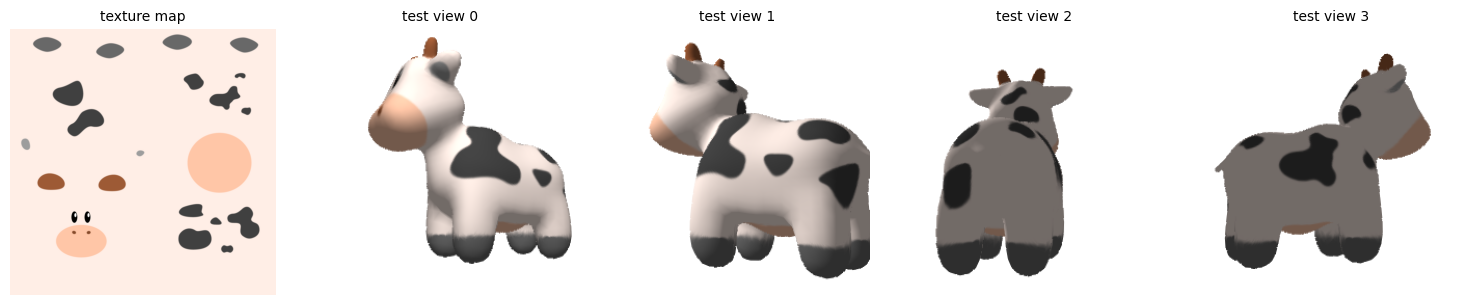

In [2]:
IMAGE_SIZE = 256

mesh, light = load_scene(device)   # textured Spot mesh and a point light
print(mesh)
print(light)

camera = OrbitCamera(image_width=IMAGE_SIZE, image_height=IMAGE_SIZE, fov_x=40, fov_y=40,
                     z_near=0.1, z_far=100, device=device)
mesh_renderer = MeshRenderer(camera=camera, bg_color=(1.0, 1.0, 1.0), light=light)
gaussian_rasterizer = GaussianRasterizer(camera=camera, bg_color=(1.0, 1.0, 1.0))
train_poses, test_poses = orbit_poses(device)   # 24 training views, 6 test views

with torch.no_grad():
    gt_train = [mesh_renderer.render(mesh, pose)[0][0] for pose in train_poses]
    gt_test = [mesh_renderer.render(mesh, pose)[0][0] for pose in test_poses]

def to_np(img):
    return img.detach().clamp(0, 1).cpu().numpy()

def show_images(images, titles, size=3.0):
    fig, axs = plt.subplots(1, len(images), figsize=(size * len(images), size))
    for ax, img, title in zip(np.atleast_1d(axs), images, titles):
        ax.imshow(to_np(img))
        ax.set_title(title, fontsize=10)
        ax.axis('off')
    plt.tight_layout()
    plt.show()

show_images([mesh.texture] + gt_test[:4], ['texture map'] + [f'test view {i}' for i in range(4)])

In [3]:
def plot_history(history, title):
    fig, axs = plt.subplots(1, 2, figsize=(8.4, 3.2))
    axs[0].plot(history['loss'], linewidth=0.6); axs[0].set_yscale('log')
    axs[0].set_title('training L1 loss'); axs[0].set_xlabel('iteration')
    axs[1].plot(history['psnr_iters'], history['psnr'], 'o-'); axs[1].set_title('test PSNR (dB)'); axs[1].set_xlabel('iteration')
    fig.suptitle(title); plt.tight_layout(); plt.show()

def show_progress(history, view=0):
    snaps = history['snapshots']
    picks = [snaps[i] for i in np.unique(np.linspace(0, len(snaps) - 1, 5).round().astype(int))]
    show_images([views[view] for _, views in picks] + [gt_test[view]],
                [f'iter {it}' for it, _ in picks] + ['ground truth'], size=2.6)

### Experiment 1: train the texture map

The texture map (512x512, through a sigmoid so it stays in `[0, 1]`) starts uniform gray. Parts of the texture map that no view sees (gaps between the uv charts, hidden surfaces) are not learned.

iter    50  loss 0.0415  (1.0s)
iter   100  loss 0.0176  (2.1s)
iter   150  loss 0.0078  (3.2s)
iter   200  loss 0.0053  (4.2s)
iter   250  loss 0.0035  (5.3s)
iter   300  loss 0.0029  (6.4s)
iter   350  loss 0.0023  (7.4s)
iter   400  loss 0.0023  (8.5s)
iter   450  loss 0.0021  (9.6s)
iter   500  loss 0.0019  (10.7s)


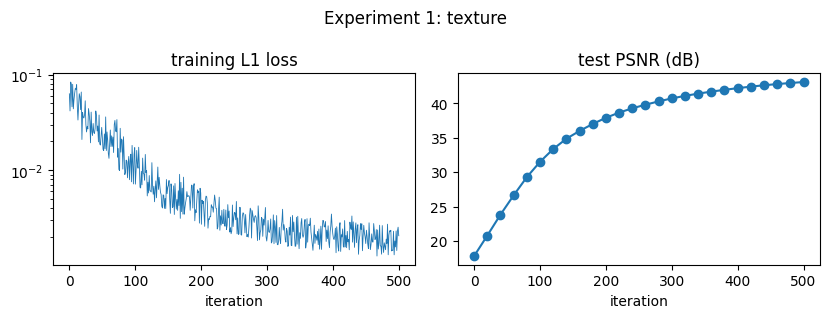

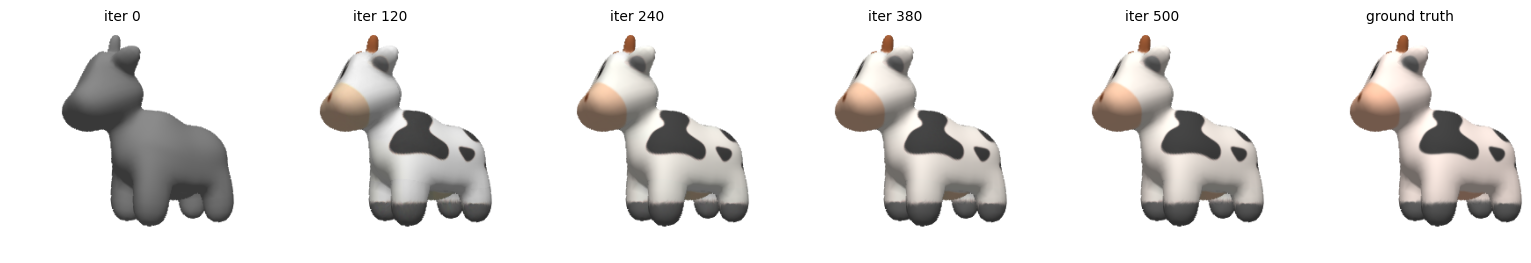

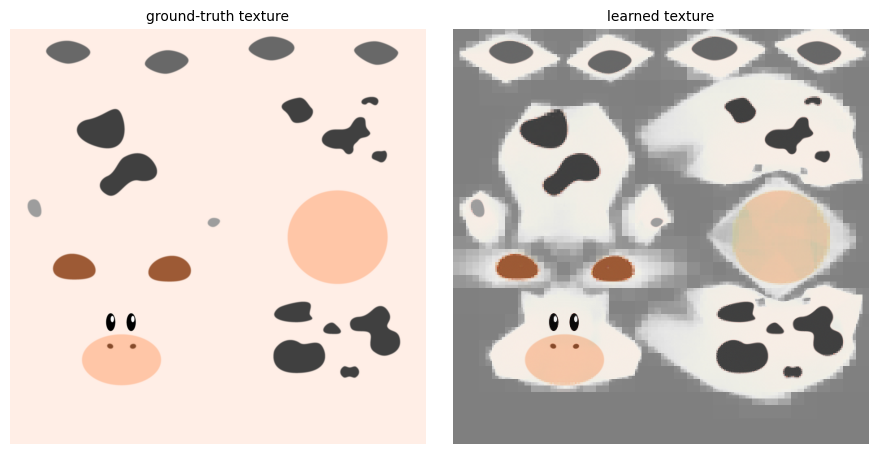

In [6]:
hist_texture = train_texture(mesh_renderer, mesh, light, gt_train, gt_test, train_poses, test_poses,
                             iters=500, tex_size=512, snapshot_every=20, log_every=50)
plot_history(hist_texture, 'Experiment 1: texture')
show_progress(hist_texture)
show_images([mesh.texture, hist_texture['texture']], ['ground-truth texture', 'learned texture'], size=4.5)

### Experiment 2: train Gaussians to mimic the mesh

3 Gaussians per triangle, placed on the mesh surface with noisy positions (0.02 std), random rotations, gray and half transparent. Only the Gaussians are rendered (no mesh), and all their parameters are trained.

17568 Gaussians
iter   300  loss 0.0256  (4.8s)
iter   600  loss 0.0054  (9.5s)
iter   900  loss 0.0045  (14.1s)
iter  1200  loss 0.0041  (18.8s)
iter  1500  loss 0.0037  (23.5s)
iter  1800  loss 0.0034  (28.1s)
iter  2100  loss 0.0034  (32.8s)
iter  2400  loss 0.0031  (37.5s)
iter  2700  loss 0.0031  (42.1s)
iter  3000  loss 0.0030  (46.8s)


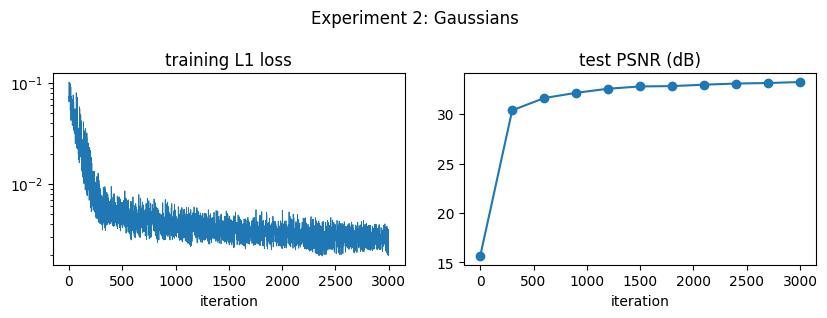

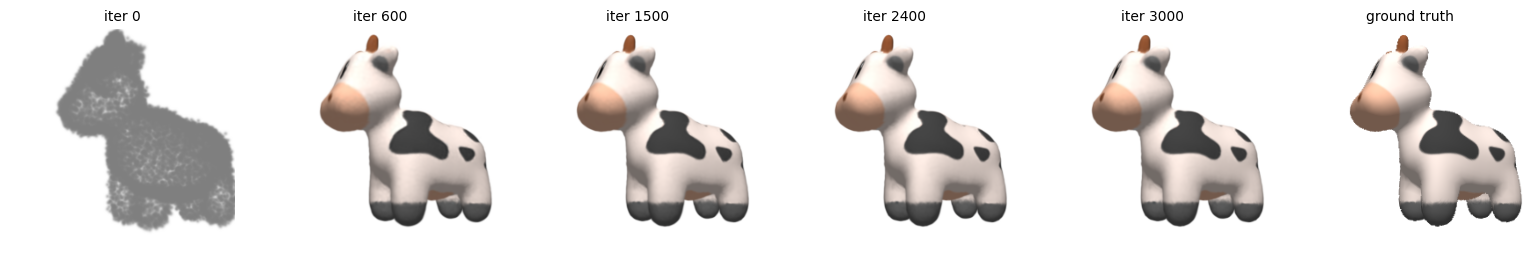

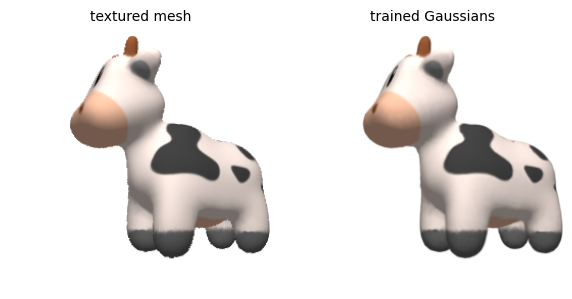

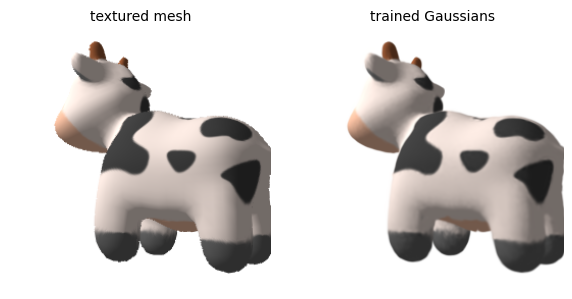

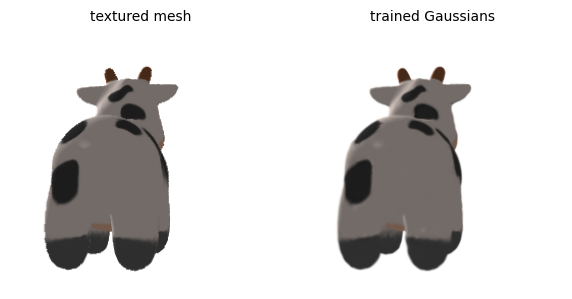

In [7]:
params = initial_gaussians(mesh, device)   # raw (unactivated) parameters
print(f"{params['means'].shape[0]} Gaussians")

hist_gaussians = train_gaussians(gaussian_rasterizer, params, gt_train, gt_test, train_poses, test_poses,
                                 iters=3000, snapshot_every=300, log_every=300)
plot_history(hist_gaussians, 'Experiment 2: Gaussians')
show_progress(hist_gaussians)

# the textured mesh and the trained Gaussians, side by side
with torch.no_grad():
    gaussians = make_gaussians(params)
    for view in range(3):
        rgb_g, _, _ = gaussian_rasterizer.rasterize(gaussians, test_poses[view])
        show_images([gt_test[view], rgb_g[0]], ['textured mesh', 'trained Gaussians'])

### Summary

A run "works" if the test PSNR clearly improves (here: by more than 10 dB).

In [8]:
for name, h in [('texture', hist_texture), ('gaussians', hist_gaussians)]:
    ok = h['psnr'][-1] > h['psnr'][0] + 10.0
    print(f"{name:10s} test PSNR {h['psnr'][0]:6.2f} -> {h['psnr'][-1]:6.2f} dB" + ('   [OK]' if ok else '   [CHECK]'))

texture    test PSNR  17.86 ->  43.10 dB   [OK]
gaussians  test PSNR  15.65 ->  33.25 dB   [OK]
